# Dự đoán khách hàng chốt sale

**Mục tiêu:** xem tương quan giữa các biến số, huấn luyện Random Forest, rồi kiểm tra chỉ số và biến quan trọng.

- Nhãn: `1` nếu `thoi_gian_chuyen_sang_chot_sale` có giá trị; ngược lại là `0`.
- Chia có phân tầng: 80% train, 15% validation, 5% test. Test chỉ dùng ở bước cuối.
- Mô hình giả định các biến tư vấn/chăm sóc đã có trước khi chốt. Nếu dự đoán ngay lúc đăng ký, cần bỏ các biến ghi nhận sau đăng ký.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

In [16]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [7]:
data = pd.read_excel("Courses_of_Interest_Processed.xlsx")
target_col = "thoi_gian_chuyen_sang_chot_sale"
y = data[target_col].notna().astype(int)
print("Data shape:", data.shape)
print("Target counts:", y.value_counts().to_dict())

Data shape: (18978, 32)
Target counts: {0: 12769, 1: 6209}


## Đặc trưng thời gian

Tách giờ, thứ và tháng từ ngày đăng ký; thêm trạng thái và khoảng ngày đến tư vấn. Không đưa thời điểm chốt hoặc cột phát sinh từ thời điểm chốt vào mô hình.

In [9]:
signup_time = pd.to_datetime(data["ngay_tao"], errors="coerce")
consult_time = pd.to_datetime(data["thoi_gian_chuyen_sang_tu_van"], errors="coerce")
data["signup_hour"] = signup_time.dt.hour
data["signup_weekday"] = signup_time.dt.dayofweek
data["signup_month"] = signup_time.dt.month

Các đặc trưng mới chỉ dùng ngày đăng ký và ngày chuyển tư vấn. Giá trị ngày âm được đánh dấu thiếu, không đổi thành trị tuyệt đối.

In [10]:
data["signup_weekend"] = data["signup_weekday"].isin([5, 6]).astype(int)
data["has_consult"] = consult_time.notna().astype(int)
data["days_to_consult"] = (consult_time - signup_time).dt.total_seconds() / 86400
data.loc[data["days_to_consult"] < 0, "days_to_consult"] = np.nan
print("Missing days-to-consult:", int(data["days_to_consult"].isna().sum()))

Missing days-to-consult: 15886


## Biến đầu vào

Dùng loại chăm sóc, nhà mạng, khóa học gốc, sentiment, tư vấn viên, cờ tên thiếu, đặc trưng tư vấn và lịch đăng ký. Bỏ ID/STT, thời điểm chốt, mã khóa suy ra, cờ lỗi hằng, `tao_lich_tu_van`/`check_zalo` gần hằng và `hieu_suat` thiếu nhiều.

In [17]:
categorical_cols = ["MKT_xu_ly_data", "nha_mang", "quan_tam_khoa_hoc", "sentimatic", "tu_van_vien"]
numeric_cols = ["loi_ten_rong", "has_consult", "days_to_consult", "signup_hour", "signup_weekday", "signup_month", "signup_weekend"]
feature_cols = categorical_cols + numeric_cols
X = data[feature_cols].copy()
X[categorical_cols] = X[categorical_cols].fillna("Chua ro").astype(str)

## Chia dữ liệu

Giữ nguyên 5% làm test cuối. Chia phần 95% còn lại thành 80% train và 15% validation. `stratify` giữ tỷ lệ chốt gần nhau giữa các tập.

In [18]:
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.05, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=15/95, stratify=y_dev, random_state=42)
print("Train / validation / test:", len(X_train), len(X_val), len(X_test))
print("Closed sales:", y_train.sum(), y_val.sum(), y_test.sum())

Train / validation / test: 15182 2847 949
Closed sales: 4967 932 310


## Ma trận tương quan

Tính Pearson trên biến số/binary của train và nhãn. Biến danh mục không đưa vào Pearson vì mã danh mục không có thứ tự số học; chúng sẽ được one-hot encode cho Random Forest.

In [13]:
corr_data = X_train[numeric_cols].copy()
corr_data = corr_data.fillna(corr_data.median())
corr_data["chot"] = y_train
corr_matrix = corr_data.corr()
display(corr_matrix.round(2))

,loi_ten_rong,has_consult,days_to_consult,signup_hour,signup_weekday,signup_month,signup_weekend,chot
loi_ten_rong,1.00,-0.06,-0.03,0.01,0.00,-0.11,-0.01,-0.01
has_consult,-0.06,1.00,0.35,-0.01,-0.00,0.13,0.01,0.01
days_to_consult,-0.03,0.35,1.00,-0.01,0.02,-0.05,0.02,-0.02
signup_hour,0.01,-0.01,-0.01,1.00,0.05,-0.11,0.05,-0.03
signup_weekday,0.00,-0.00,0.02,0.05,1.00,0.02,0.75,0.02
signup_month,-0.11,0.13,-0.05,-0.11,0.02,1.00,0.06,0.21
signup_weekend,-0.01,0.01,0.02,0.05,0.75,0.06,1.00,0.03
chot,-0.01,0.01,-0.02,-0.03,0.02,0.21,0.03,1.00


`signup_weekday` và `signup_weekend` có liên hệ vì weekend được tạo từ thứ trong tuần. Ma trận chỉ phản ánh tương quan tuyến tính; mức quan trọng cuối cùng sẽ xem từ Random Forest.

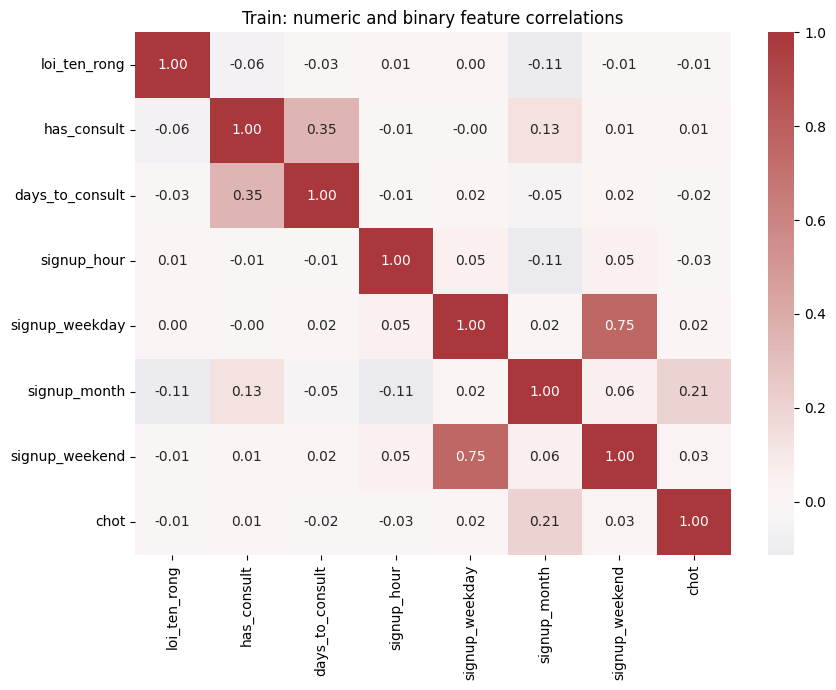

In [14]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Train: numeric and binary feature correlations")
plt.tight_layout()
plt.show()

## Preprocessing

Median cho cột số, giá trị xuất hiện nhiều nhất cho danh mục, sau đó one-hot encode. Bộ xử lý chỉ `fit` trên train; validation và test chỉ `transform`.

In [19]:
numeric_pipe = Pipeline([
    ("fill", SimpleImputer(strategy="median")),
])

In [23]:
category_pipe = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=25, drop="first", sparse_output=False)),
])

In [24]:
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipe, numeric_cols),
    ("category", category_pipe, categorical_cols),
])

In [25]:
X_train_encoded = preprocessor.fit_transform(X_train)
X_val_encoded = preprocessor.transform(X_val)
feature_names = preprocessor.get_feature_names_out()
print("Encoded train / validation:", X_train_encoded.shape, X_val_encoded.shape)

Encoded train / validation: (15182, 56) (2847, 56)


c:\Users\PH315-54\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


## Huấn luyện Random Forest

Train mô hình trên 80% dữ liệu. Validation dùng để xem chất lượng mô hình; test vẫn để riêng đến bước đánh giá cuối.

In [26]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [27]:
rf_model = RandomForestClassifier(
    n_estimators=300, max_features="sqrt",
    min_samples_leaf=5, class_weight="balanced",
    random_state=42, n_jobs=-1,
)

In [28]:
rf_model.fit(X_train_encoded, y_train)
val_probability = rf_model.predict_proba(X_val_encoded)[:, 1]
val_prediction = (val_probability >= 0.5).astype(int)
print("Validation predictions:", len(val_prediction))

Validation predictions: 2847


## Kiểm tra validation

Các chỉ số dưới đây dùng ngưỡng phân loại mặc định 0,5. ROC-AUC và PR-AUC dùng xác suất; test vẫn chưa được xem.

In [29]:
val_metrics = pd.Series({
    "Accuracy": accuracy_score(y_val, val_prediction),
    "Precision": precision_score(y_val, val_prediction),
    "Recall": recall_score(y_val, val_prediction),
})

In [30]:
val_metrics["F1"] = f1_score(y_val, val_prediction)
val_metrics["ROC-AUC"] = roc_auc_score(y_val, val_probability)
val_metrics["PR-AUC"] = average_precision_score(y_val, val_probability)
display(val_metrics.round(3))

Accuracy     0.776
Precision    0.620
Recall       0.813
F1           0.703
ROC-AUC      0.860
PR-AUC       0.727
dtype: float64

### Confusion matrix validation

Hàng là nhãn thật, cột là dự đoán. Dùng để xem mô hình bỏ sót khách chốt hay báo nhầm khách chưa chốt.

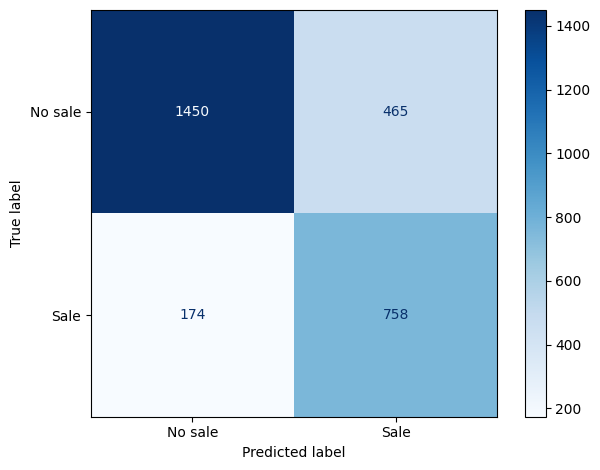

In [31]:
val_matrix = confusion_matrix(y_val, val_prediction)
val_plot = ConfusionMatrixDisplay(val_matrix, display_labels=["No sale", "Sale"])
val_plot.plot(cmap="Blues", values_format="d")
plt.tight_layout()
plt.show()

## Biến quan trọng

Random Forest trả importance cho từng cột sau one-hot. Gộp importance theo tên biến gốc để dễ xem biến nào đóng góp nhiều nhất.

In [32]:
def source_feature(encoded_name):
    for column in categorical_cols:
        if encoded_name.startswith(f"category__{column}_"):
            return column
    return encoded_name.replace("numeric__", "")

In [33]:
importance = pd.DataFrame({"feature": feature_names, "importance": rf_model.feature_importances_})
importance["variable"] = importance["feature"].apply(source_feature)
importance_by_variable = importance.groupby("variable", as_index=False)["importance"].sum()
importance_by_variable = importance_by_variable.sort_values("importance", ascending=False)
display(importance_by_variable.head(12).round(4))

,variable,importance
11,tu_van_vien,0.4125
8,signup_month,0.2523
5,quan_tam_khoa_hoc,0.0834
0,MKT_xu_ly_data,0.0640
7,signup_hour,0.0451
9,signup_weekday,0.0355
1,days_to_consult,0.0302
6,sentimatic,0.0229
4,nha_mang,0.0223
2,has_consult,0.0176


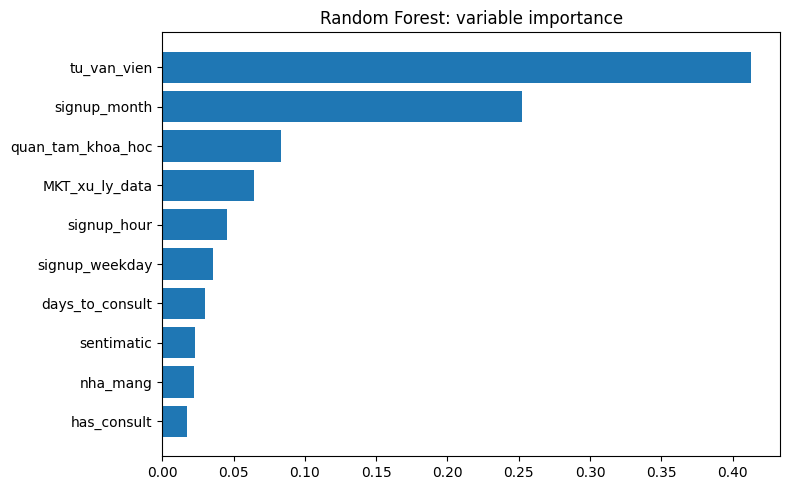

In [34]:
top_importance = importance_by_variable.head(10).sort_values("importance")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_importance["variable"], top_importance["importance"])
ax.set_title("Random Forest: variable importance")
plt.tight_layout()
plt.show()

## Đánh giá test cuối

Test 5% được giữ riêng. Không dùng tập này để chọn biến, chỉnh tham số hay chọn ngưỡng; ở đây chỉ tính kết quả cuối cùng với ngưỡng 0,5.

In [35]:
X_test_encoded = preprocessor.transform(X_test)
test_probability = rf_model.predict_proba(X_test_encoded)[:, 1]
test_prediction = (test_probability >= 0.5).astype(int)
print("Test rows:", len(test_prediction))

Test rows: 949


c:\Users\PH315-54\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [36]:
test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, test_prediction),
    "Precision": precision_score(y_test, test_prediction),
    "Recall": recall_score(y_test, test_prediction),
})

In [37]:
test_metrics["F1"] = f1_score(y_test, test_prediction)
test_metrics["ROC-AUC"] = roc_auc_score(y_test, test_probability)
test_metrics["PR-AUC"] = average_precision_score(y_test, test_probability)
display(test_metrics.round(3))

Accuracy     0.774
Precision    0.616
Recall       0.823
F1           0.704
ROC-AUC      0.863
PR-AUC       0.732
dtype: float64